# 05 — Season replay

Replays one past season as if we had used the model live.

1. **Freeze the model:** train it once on every match *before* the season starts, then never update it.
2. **Predict every match of the season:** for each match the model gets only the two teams' form from their
   **last 5 matches before kickoff** (which can include earlier games of the same season) and their **points per
   game this season so far** (the league table before kickoff).
3. **Compare with what really happened.**

In one sentence: *the model learned from all seasons before this one and was then frozen; for each match it was
given only the two teams' last 5 games and season record before kickoff, so it never saw the result it was predicting.*

**Which season?** Any season from 2017/18 on works. **2025/26 is the best choice**: the model is frozen before it
starts and never sees its results. Be aware of two small things: 2024/25 was used to choose the regularisation
strength in notebook 02, and the decision to add the league-table feature was made after comparing results over
2019/20–2026/27, which includes 2025/26. Both effects are small, but mention them if asked.

In [1]:
# ---- Settings ----
SEASON = 2526     # 2526 = 2025/26, 2425 = 2024/25, 2324 = 2023/24, ...
MODEL = "Poisson" # model used in the match tables: "Poisson" or "Logistic"
TEAM = "Arsenal"  # team for the "one team's season" section

In [2]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import PROCESSED_DIR, load_processed
from src.evaluation import CLASSES, paired_difference, probs_of, rps_per_match, score_table
from src.predict import PROB_COLS, season_replay

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 400)
COLORS = {"Baseline": "#a0aec0", "Logistic": "#2b6cb0", "Poisson": "#c05621"}
NAMES = {"H": "home win", "D": "draw", "A": "away win"}
LABEL = f"20{str(SEASON)[:2]}/{str(SEASON)[2:]}"

## 0. Run the tests first

In [3]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], cwd=PROJECT_ROOT,
                        capture_output=True, text=True, timeout=300)
print(result.stdout[-1500:] or result.stderr[-1500:])

........................................................................ [ 93%]
.....                                                                    [100%]
77 passed in 3.95s



## 1. Freeze the model and predict the season

In [4]:
features = load_processed()
replay, info = season_replay(features, SEASON)

print(f"Season {LABEL}: first match {info['season_start']:%d %b %Y}")
print(f"Model trained on {info['trained_on']} matches, "
      f"{info['trained_from']:%b %Y} to {info['trained_to']:%d %b %Y}, then frozen.")
n_pred = replay[replay['model'] == 'Baseline'].shape[0]
print(f"Predicted {n_pred} of {info['season_matches']} matches.")
if len(info["not_predicted"]):
    counts = pd.concat([info["not_predicted"]["home_team"], info["not_predicted"]["away_team"]]).value_counts()
    print(f"\nNot predicted ({len(info['not_predicted'])}), because a team had too few earlier Premier League "
          "matches (usually promoted teams new to the data):")
    print(info["not_predicted"].assign(date=info["not_predicted"]["date"].dt.date).to_string(index=False))

path = PROCESSED_DIR / f"season_replay_{SEASON}.csv"
replay.to_csv(path, index=False)
print(f"\nSaved to {path.relative_to(PROJECT_ROOT)}")

Season 2025/26: first match 15 Aug 2025
Model trained on 3276 matches, Aug 2016 to 25 May 2025, then frozen.
Predicted 380 of 380 matches.

Saved to data/processed/season_replay_2526.csv


## 2. How good were the predictions?

Lower is better for log loss, Brier and RPS (see notebook 03). The **baseline** ignores the teams and always predicts
the historical share of home wins, draws and away wins. **Always 1/3** is pure guessing.

In [5]:
results, _ = probs_of(replay, "Baseline")
predictions = {m: probs_of(replay, m)[1] for m in ["Baseline", "Logistic", "Poisson"]}
scores = score_table(results, {"Always 1/3": np.full((len(results), 3), 1 / 3), **predictions})
scores.loc["Always 1/3", "accuracy"] = np.nan   # no favourite when all three are equal

d = paired_difference(results, predictions[MODEL], predictions["Baseline"], "RPS")
print(f"{LABEL}: {len(results)} matches. Actual: {(results == 'H').mean():.0%} home wins, "
      f"{(results == 'D').mean():.0%} draws, {(results == 'A').mean():.0%} away wins.")
print(f"{MODEL} vs baseline, RPS difference per match: {d['mean diff']:+.4f} "
      f"(95% interval {d['ci low']:+.4f} to {d['ci high']:+.4f}; negative = model better)")
scores.round(4)

2025/26: 380 matches. Actual: 43% home wins, 27% draws, 30% away wins.
Poisson vs baseline, RPS difference per match: -0.0141 (95% interval -0.0252 to -0.0030; negative = model better)


,log loss,Brier,RPS,accuracy
Always 1/3,1.0986,0.6667,0.2322,NaN
Baseline,1.0851,0.6565,0.2278,0.4263
Logistic,1.0413,0.6267,0.2135,0.4632
Poisson,1.0434,0.6278,0.2137,0.4763


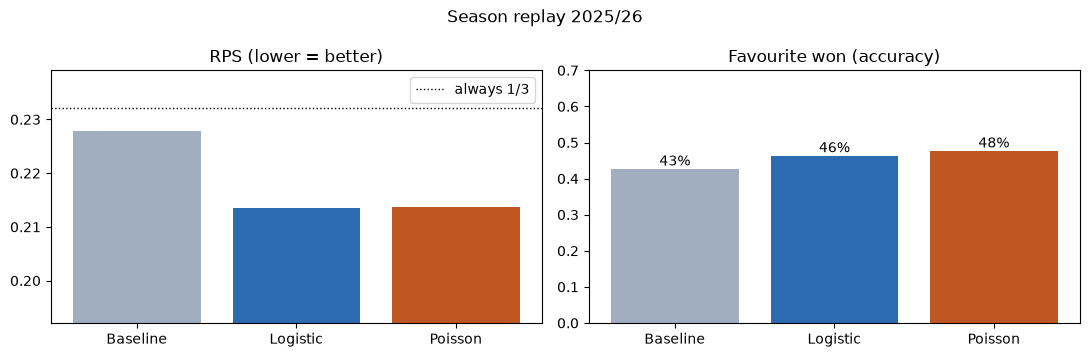

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
order = ["Baseline", "Logistic", "Poisson"]
ax.bar(order, scores.loc[order, "RPS"], color=[COLORS[m] for m in order])
ax.axhline(scores.loc["Always 1/3", "RPS"], color="black", ls=":", lw=1, label="always 1/3")
lo = scores.loc[order, "RPS"].min()
ax.set_ylim(lo * 0.9, scores.loc["Always 1/3", "RPS"] * 1.03)
ax.set_title("RPS (lower = better)")
ax.legend()
ax = axes[1]
ax.bar(order, scores.loc[order, "accuracy"], color=[COLORS[m] for m in order])
for i, m in enumerate(order):
    ax.text(i, scores.loc[m, "accuracy"] + 0.01, f"{scores.loc[m, 'accuracy']:.0%}", ha="center")
ax.set_ylim(0, 0.7)
ax.set_title("Favourite won (accuracy)")
plt.suptitle(f"Season replay {LABEL}")
plt.tight_layout()
plt.show()

### Through the season

Running average of RPS from the first match onwards. The model's line staying below the baseline's means it was
better throughout the season, not only in a lucky spell.

**Read the first weeks with care.** Early on the average covers only a handful of matches, so it jumps around.
Also, in August each team's "last 5 matches" are mostly from the *previous* season, before summer transfers, so
early-season form is the least reliable. Watch where the lines settle.

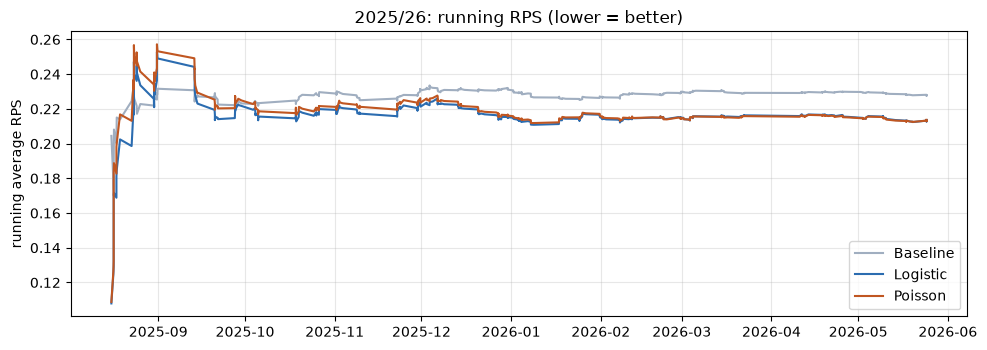

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for m in order:
    rows = replay[replay["model"] == m].sort_values("date")
    per = rps_per_match(rows["result"], rows[PROB_COLS].to_numpy())
    running = pd.Series(per).expanding().mean()
    ax.plot(rows["date"].to_numpy(), running.to_numpy(), color=COLORS[m], label=m)
ax.set_ylabel("running average RPS")
ax.set_title(f"{LABEL}: running RPS (lower = better)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3. Every match: prediction vs result

One row per match (model chosen in the settings). **Chance given** is the probability the model gave to what actually
happened.

In [8]:
p = replay[replay["model"] == MODEL].sort_values("date").reset_index(drop=True)
probs = p[PROB_COLS].to_numpy()
actual = p["result"].map(CLASSES.index).to_numpy()
chance = probs[np.arange(len(p)), actual]     # probability given to what happened
fav = probs.argmax(axis=1)
table = pd.DataFrame({
    "date": p["date"].dt.date,
    "match": p["home_team"] + " vs " + p["away_team"],
    "home": p["p_H"].map("{:.0%}".format),
    "draw": p["p_D"].map("{:.0%}".format),
    "away": p["p_A"].map("{:.0%}".format),
    "score": p["home_goals"].astype(int).astype(str) + "-" + p["away_goals"].astype(int).astype(str),
    "result": p["result"].map(NAMES),
    "chance given": [f"{c:.0%}" for c in chance],
    "favourite won": fav == actual,
})
table["_chance"] = chance
print(f"{len(table)} matches. Showing the first 20; the full table is in `table` and in the saved CSV.")
table.drop(columns="_chance").head(20)

380 matches. Showing the first 20; the full table is in `table` and in the saved CSV.


,date,match,home,draw,away,score,result,chance given,favourite won
0,2025-08-15,Liverpool vs Bournemouth,58%,21%,21%,4-2,home win,58%,True
1,2025-08-16,Aston Villa vs Newcastle United,34%,24%,41%,0-0,draw,24%,False
2,2025-08-16,Brighton vs Fulham,43%,25%,32%,1-1,draw,25%,False
3,2025-08-16,Sunderland vs West Ham,34%,26%,40%,3-0,home win,34%,False
4,2025-08-16,Tottenham vs Burnley,42%,24%,34%,3-0,home win,42%,True
5,2025-08-16,Wolverhampton Wanderers vs Manchester City,32%,25%,43%,0-4,away win,43%,True
6,2025-08-17,Chelsea vs Crystal Palace,43%,24%,33%,0-0,draw,24%,False
7,2025-08-17,Nottingham Forest vs Brentford,33%,25%,41%,3-1,home win,33%,False
8,2025-08-17,Manchester United vs Arsenal,33%,24%,43%,0-1,away win,43%,True
9,2025-08-18,Leeds vs Everton,28%,25%,47%,1-0,home win,28%,False


## 4. Biggest upsets

The results the model thought least likely. Every season has some; a model that says "20%" *should* be wrong
about 1 time in 5 at that level.

In [9]:
table.nsmallest(10, "_chance").drop(columns="_chance")

,date,match,home,draw,away,score,result,chance given,favourite won
284,2026-03-03,Wolverhampton Wanderers vs Liverpool,11%,16%,73%,2-1,home win,11%,False
97,2025-11-02,West Ham vs Newcastle United,11%,17%,72%,3-1,home win,11%,False
27,2025-08-31,Nottingham Forest vs West Ham,70%,18%,12%,0-3,away win,12%,False
14,2025-08-23,Burnley vs Sunderland,13%,19%,68%,2-0,home win,13%,False
211,2026-01-17,Tottenham vs West Ham,65%,21%,14%,1-2,away win,14%,False
260,2026-02-18,Wolverhampton Wanderers vs Arsenal,8%,15%,77%,2-2,draw,15%,False
185,2025-12-30,Manchester United vs Wolverhampton Wanderers,77%,15%,8%,1-1,draw,15%,False
263,2026-02-21,Chelsea vs Burnley,72%,17%,11%,1-1,draw,17%,False
225,2026-01-25,Brentford vs Nottingham Forest,62%,21%,17%,0-2,away win,17%,False
139,2025-12-04,Manchester United vs West Ham,72%,17%,11%,1-1,draw,17%,False


## 5. Most confident correct calls

In [10]:
table[table["favourite won"]].nlargest(10, "_chance").drop(columns="_chance")

,date,match,home,draw,away,score,result,chance given,favourite won
153,2025-12-13,Arsenal vs Wolverhampton Wanderers,86%,9%,4%,2-1,home win,86%,True
162,2025-12-20,Manchester City vs West Ham,79%,13%,8%,3-0,home win,79%,True
367,2026-05-18,Arsenal vs Burnley,76%,15%,9%,1-0,home win,76%,True
87,2025-10-26,Bournemouth vs Nottingham Forest,75%,15%,10%,2-0,home win,75%,True
110,2025-11-22,Burnley vs Chelsea,11%,16%,73%,0-2,away win,73%,True
352,2026-05-09,Brighton vs Wolverhampton Wanderers,72%,17%,11%,3-0,home win,72%,True
174,2025-12-27,Liverpool vs Wolverhampton Wanderers,72%,17%,10%,2-1,home win,72%,True
120,2025-11-29,Brentford vs Burnley,71%,17%,11%,3-1,home win,71%,True
62,2025-10-04,Arsenal vs West Ham,71%,18%,11%,2-0,home win,71%,True
242,2026-02-07,Arsenal vs Sunderland,71%,18%,11%,3-0,home win,71%,True


## 6. Could you trust the percentages?

Matches grouped by how confident the model was in its favourite. If the model is honest, the favourite should win
about as often as predicted. **Draws as favourite** are rare; the model almost always favours one team.

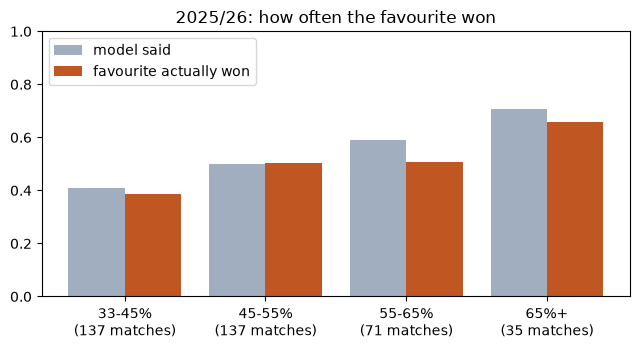

,matches,avg_predicted,favourite_won
group,,,
33-45%,137,0.410,0.387
45-55%,137,0.499,0.504
55-65%,71,0.592,0.507
65%+,35,0.706,0.657


In [11]:
top = p[PROB_COLS].to_numpy().max(axis=1)
won = fav == actual
bins = [0.33, 0.45, 0.55, 0.65, 1.0]
labels = ["33-45%", "45-55%", "55-65%", "65%+"]
group = pd.cut(top, bins=bins, labels=labels, include_lowest=True)
calib = pd.DataFrame({"group": group, "predicted": top, "won": won}).groupby("group", observed=True).agg(
    matches=("won", "size"), avg_predicted=("predicted", "mean"), favourite_won=("won", "mean"))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(calib))
ax.bar(x - 0.2, calib["avg_predicted"], width=0.4, color="#a0aec0", label="model said")
ax.bar(x + 0.2, calib["favourite_won"], width=0.4, color=COLORS[MODEL], label="favourite actually won")
ax.set_xticks(x, [f"{g}\n({n} matches)" for g, n in zip(calib.index, calib["matches"])])
ax.set_ylim(0, 1)
ax.set_title(f"{LABEL}: how often the favourite won")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
calib.round(3)

## 7. One team's season

Change `TEAM` in the settings cell. Shows each of the team's matches from the team's point of view.

In [12]:
t = table[table["match"].str.startswith(TEAM + " vs ") | table["match"].str.endswith(" vs " + TEAM)]
if t.empty:
    print(f"No predicted matches for '{TEAM}' in {LABEL}. Check the spelling, e.g. 'Manchester City'.")
else:
    pt = p.loc[t.index]
    is_home = pt["home_team"] == TEAM
    team_win = np.where(is_home, pt["p_H"], pt["p_A"])
    team_res = np.where(pt["result"] == "D", "D", np.where((pt["result"] == "H") == is_home, "W", "L"))
    view = pd.DataFrame({
        "date": t["date"], "opponent": np.where(is_home, pt["away_team"], pt["home_team"]),
        "venue": np.where(is_home, "home", "away"),
        f"P({TEAM} win)": [f"{v:.0%}" for v in team_win], "P(draw)": t["draw"],
        "score": t["score"], "result": team_res,
    })
    print(f"{TEAM} in {LABEL}: {len(view)} predicted matches, "
          f"W{(team_res == 'W').sum()} D{(team_res == 'D').sum()} L{(team_res == 'L').sum()}; "
          f"average predicted win chance {team_win.mean():.0%}, actual win rate {(team_res == 'W').mean():.0%}.")
    display(view.reset_index(drop=True))

Arsenal in 2025/26: 38 predicted matches, W26 D7 L5; average predicted win chance 57%, actual win rate 68%.


,date,opponent,venue,P(Arsenal win),P(draw),score,result
0,2025-08-17,Manchester United,away,43%,24%,0-1,W
1,2025-08-23,Leeds,home,51%,23%,5-0,W
2,2025-08-31,Liverpool,away,31%,22%,1-0,L
3,2025-09-13,Nottingham Forest,home,54%,24%,3-0,W
4,2025-09-21,Manchester City,home,53%,23%,1-1,D
5,2025-09-28,Newcastle United,away,37%,28%,1-2,W
6,2025-10-04,West Ham,home,71%,18%,2-0,W
7,2025-10-18,Fulham,away,53%,24%,0-1,W
8,2025-10-26,Crystal Palace,home,53%,22%,1-0,W
9,2025-11-01,Burnley,away,65%,20%,0-2,W


## 8. Summary for the presentation

In [13]:
s = scores
print(f"Season replay {LABEL}")
print(f"  Model frozen after training on {info['trained_on']} matches "
      f"({info['trained_from']:%b %Y} - {info['trained_to']:%b %Y}).")
print(f"  Predicted {len(results)} of {info['season_matches']} matches using only each team's last 5 games and season record before kickoff.")
print()
for m in ["Always 1/3", "Baseline", "Logistic", "Poisson"]:
    acc = "" if m == "Always 1/3" else f"   favourite won {s.loc[m, 'accuracy']:.0%}"
    print(f"  {m:<11} RPS {s.loc[m, 'RPS']:.4f}   log loss {s.loc[m, 'log loss']:.4f}{acc}")
print()
better = "better" if d["ci high"] < 0 else ("worse" if d["ci low"] > 0 else "not clearly different")
print(f"  {MODEL} vs baseline: {better} (RPS {d['mean diff']:+.4f}, 95% interval {d['ci low']:+.4f} to {d['ci high']:+.4f}).")

Season replay 2025/26
  Model frozen after training on 3276 matches (Aug 2016 - May 2025).
  Predicted 380 of 380 matches using only each team's last 5 games and season record before kickoff.

  Always 1/3  RPS 0.2322   log loss 1.0986
  Baseline    RPS 0.2278   log loss 1.0851   favourite won 43%
  Logistic    RPS 0.2135   log loss 1.0413   favourite won 46%
  Poisson     RPS 0.2137   log loss 1.0434   favourite won 48%

  Poisson vs baseline: better (RPS -0.0141, 95% interval -0.0252 to -0.0030).
